# ДЗ № 7: связанные колебания двух тележек

*Вдохновлено семинарскими заданиями доц. Полуяна С.В.*

Две одинаковые тележки соединены тремя пружинами. Продолжим работу с линейными
ДУ второго порядка, но теперь у системы две координаты. Внешняя гармоническая
сила действует только на первую тележку. Главный приём задания — заменить две
связанные координаты их суммой и разностью; получатся два обычных ДУ, которые
можно решить `SymPy`.

**Что сдавать:** выполненный ноутбук с рабочим кодом `sp.Eq`,
`sp.dsolve(..., ics=...)` и подписанными графиками. Не вводите готовые формулы
решения вручную: получите решения для $u$ и $v$ через `dsolve`, затем
восстановите $x_1,x_2$.

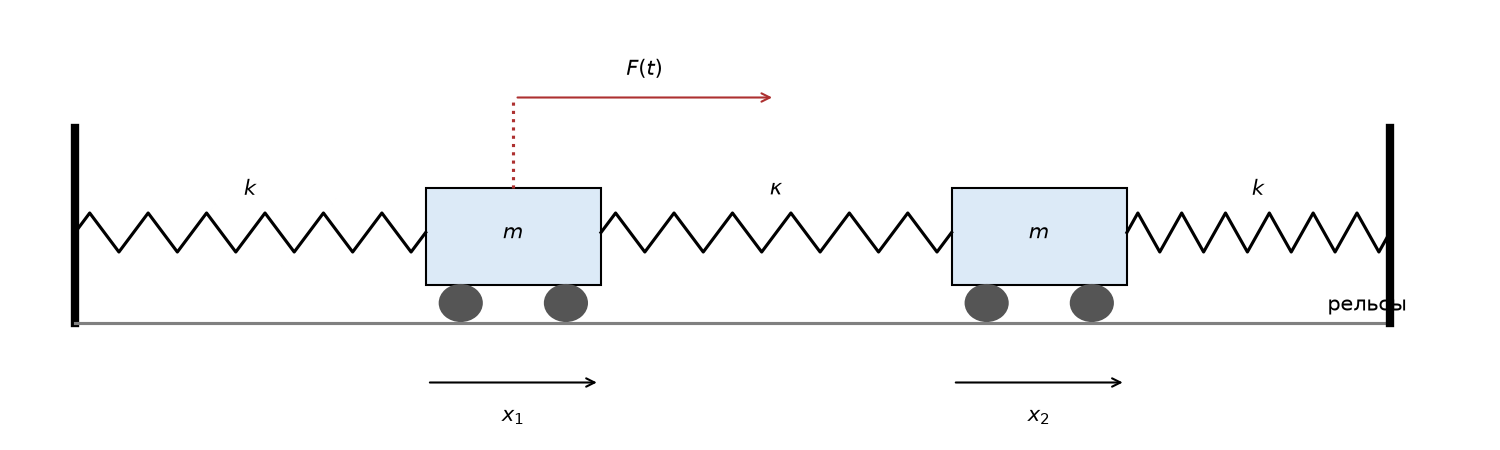

Стрелки координат задают положительное направление смещений от равновесия. Стрелка силы показывает её положительное направление; знак силы может меняться.

## Модель и данные

Положительное направление обеих осей — вправо; $x_1(t)$ и $x_2(t)$ — смещения
тележек от положения равновесия. Крайние пружины имеют жёсткость $k$, средняя —
$\kappa$. Удлинение средней пружины равно $x_2-x_1$. Поэтому на первую тележку
она действует силой $\kappa(x_2-x_1)$, а на вторую — противоположной силой
$\kappa(x_1-x_2)$. На каждую тележку действует вязкое сопротивление
$-c x_i'$. Внешняя сила приложена только к первой тележке:
$$F(t)=F_0\cos(\Omega t).$$

Готовая система уравнений движения:
$$mx_1''+cx_1'+(k+\kappa)x_1-\kappa x_2=F(t),\qquad
mx_2''+cx_2'-\kappa x_1+(k+\kappa)x_2=0.$$

Во всём задании используйте
$$m=1\ \text{кг},\quad F_0=\frac15\ \text{Н},\quad
\Omega=3\ \text{рад/с},$$
$$x_1(0)=x_2(0)=x_1'(0)=x_2'(0)=0,\qquad 0\le t\le20\ \text{с}.$$

Ни в одном из наборов параметров ниже частота $\Omega=3$ рад/с не совпадает с
собственной частотой системы без трения.

## Задача 1. Разделение связанных уравнений

Введём сумму и разность координат:
$$u=x_1+x_2,\qquad v=x_1-x_2.$$ 

После сложения и вычитания готовой системы получаются независимые уравнения:
$$mu''+cu'+ku=F(t),\qquad mv''+cv'+(k+2\kappa)v=F(t).$$
Обратная замена:
$$x_1=\frac{u+v}{2},\qquad x_2=\frac{u-v}{2}.$$
При заданном состоянии покоя начальные условия для обеих новых функций и их
производных также равны нулю.

Для каждого набора параметров из следующей задачи запишите эти два уравнения
как `sp.Eq`, решите их `sp.dsolve(..., ics=...)` и восстановите $x_1(t),x_2(t)$.
Для `dsolve` объявите `u = sp.Function('u')` и `v = sp.Function('v')`.

In [ ]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

t = sp.symbols('t', real=True)
u = sp.Function('u')
v = sp.Function('v')
m = sp.Integer(1)
F0, Omega = sp.Rational(1, 5), sp.Integer(3)
force = F0 * sp.cos(Omega*t)
tt = np.linspace(0, 20, 2001)

# ЗАДАНИЕ: Внесите значения k, kap и c из первого набора параметров ниже.
# ЗАДАНИЕ: Запишите ode_u и ode_v через sp.Eq.
# ЗАДАНИЕ: Решите оба уравнения с помощью sp.dsolve(..., ics=...).
#       Все четыре начальных значения для u, u', v и v' равны нулю.
# ЗАДАНИЕ: Возьмите правые части решений и восстановите x1_solution и x2_solution.

## Задача 2. Фазовые портреты

Для каждого из трёх наборов параметров решите систему способом из задачи 1 и
постройте фазовые портреты на отрезке $[0,20]$ с:

| Набор | $k$, Н/м | $\kappa$, Н/м | $c$, кг/с |
|---|---:|---:|---:|
| 1. Без трения | $1$ | $3/2$ | $0$ |
| 2. Умеренное трение | $1$ | $3/2$ | $1/2$ |
| 3. Более жёсткие пружины | $2$ | $2$ | $1/2$ |

Для каждой тележки фазовый портрет — это кривая $x_i'(t)$ от $x_i(t)$:
по горизонтали откладывайте смещение в метрах, по вертикали — скорость в м/с.
Сделайте одну фигуру с двумя осями: для первой и второй тележек. На каждой оси
должны быть три кривые (по одной на набор параметров), легенда, сетка и русский
заголовок.

In [ ]:
# ЗАДАНИЕ: Создайте список из трёх наборов (название, k, kap, c) из условия.
# ЗАДАНИЕ: Для каждого набора решите уравнения для u и v через dsolve,
#       восстановите x1 и x2 и найдите скорости через sp.diff.
# ЗАДАНИЕ: Преобразуйте четыре выражения в численные функции через sp.lambdify.
# ЗАДАНИЕ: Постройте две фазовые траектории x1'(t) от x1(t) и x2'(t) от x2(t)
#       на одной фигуре для всех трёх наборов параметров.